# Does the mouse learn where in the trial it must keep still? (wheel, training sessions)
Oct 2026 \
author: Inês Laranjeira (drafted with Claude)

**Motivation.** In session 1, mice that go on to learn slowly move the wheel more in the free,
pre-trial window, while the response itself is the same
(`paper-individuality/learning_individuality/whisk_wheel_engagement.ipynb`, section 7b). One reading
is that slow learners are slower to learn the task's *structure*: which epochs require stillness and
which do not. This notebook is **step 1** of testing that. It defines per-session wheel measures of
epoch structure and plots how they change over training. It is descriptive: there are no tests yet,
and the timing and prediction analyses come later.

**Measures** (computed in `epoch_structure.py`, one row per session):
* **Movement onsets:** speed above 0.1 rad/s for at least 0.1 s, with dips shorter than 0.1 s bridged,
  on the raw ~30 Hz wheel trace.
* **Windows per trial:**
  * **stillness required:** trial start → go cue. Every onset here restarts the quiescence timer.
  * **movement free:** feedback → next trial start.
* **Per session:**
  * the **violation rate** (onsets per second in stillness windows);
  * the **free-movement rate** (onsets per second in free windows);
  * the fraction of trials with at least one violation;
  * the **selectivity** = log(free rate / violation rate). It is 0 if the mouse moves the same whether
    or not stillness is required, and above 0 if it keeps still selectively where the task demands it;
  * task performance: accuracy on easy trials, median reaction time, trials per minute.

**Cohort.** All trainingChoiceWorld sessions before proficiency with a wheel design matrix on this
machine. Trajectories use the **mice with every training session**; mice with only their first few
sessions are left out of the trajectories, so that each line follows one complete mouse. Two sessions
(CSH_ZAD_025, sessions 1–2) are excluded: in them, about 20% of the "movement" is velocity
interpolated across gaps in the wheel data (`flat_share` > 1%).

**Learning speed** (`LS_DEF`, set in the next cell):
* `'third_contrast'` (default): sessions until the protocol adds the third contrast (0.25). This is
  the first stage criterion, reached at a median of 10 sessions. It is scored inside training, so
  trajectories can also be aligned to it. Left-censored mice are dropped (DY_010, PL034: their first
  recorded session already has three contrasts), as is SWC_065, which never reaches it. Across 99
  mice it correlates ρ = +0.71 with sessions to proficiency, so it is largely the same construct
  measured earlier, not an independent axis.
* `'proficiency'`: training sessions before proficiency, as in `lab_controls.py`.

Higher = slower in both.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = pathlib.Path.cwd()
sys.path.insert(0, str(HERE.parent / 'paper-individuality'))
import paper_style as ps
ps.use('paper')
import epoch_structure as es

LS_DEF = 'third_contrast'          # or 'proficiency'

S = es.build()                     # cached; es.build(refresh=True) recomputes (~30 s)
LS = es.learning_speed(LS_DEF)
S['log_train'] = S['mouse_name'].map(LS)
S3 = es.sessions_to_third_contrast(verbose=False)
S['rel_3c'] = S['session_index'] - S['mouse_name'].map(S3)      # 0 = first session with 3 contrasts
C = S[S['complete'] & S['log_train'].notna() & ~S['qc_flat']].copy()
terc = pd.qcut(C.drop_duplicates('mouse_name').set_index('mouse_name')['log_train'], 3,
               labels=['fast', 'middle', 'slow'])
C['tercile'] = C['mouse_name'].map(terc)
T_COL = {'fast': '#2166AC', 'middle': '#8C8C8C', 'slow': '#B2182B'}

print(f"all: {len(S)} sessions, {S.mouse_name.nunique()} mice | complete: {len(C)} sessions, "
      f"{C.mouse_name.nunique()} mice")
print(f'learning speed = {LS_DEF}; per mouse, by learning-speed third:')
M1 = C.drop_duplicates('mouse_name').assign(sessions_to_3c=lambda d: d.mouse_name.map(S3))
print(M1.groupby('tercile', observed=True)[['sessions_to_3c', 'n_sessions_total']]
      .agg(['count', 'min', 'median', 'max']).to_string())

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


third contrast: 2 left-censored ['DY_010', 'PL034'], 1 never reach it ['SWC_065']


all: 1280 sessions, 101 mice | complete: 1138 sessions, 61 mice
learning speed = third_contrast; per mouse, by learning-speed third:
        sessions_to_3c                    n_sessions_total               
                 count   min median   max            count min median max
tercile                                                                  
fast                21   2.0    6.0   7.0               21   4   10.0  25
middle              22   8.0   11.0  12.0               22   9   15.0  38
slow                18  13.0   18.0  26.0               18  13   27.0  48


## Sanity check 1: what the windows and onsets look like

A 40-s stretch of the wheel trace from the first session and from the last training session of one
mouse. Blue shading = stillness required, green = movement free, unshaded = response (go cue →
feedback). Ticks = detected movement onsets.

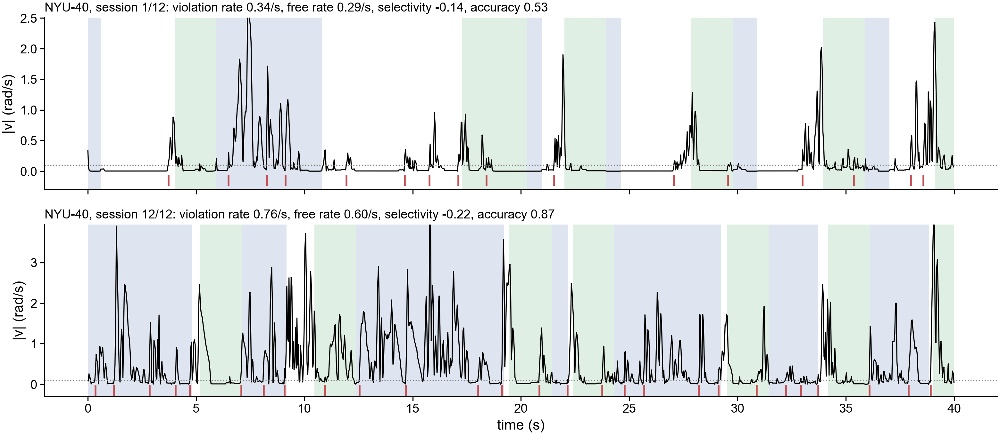

In [2]:
def show_stretch(ax, mouse, session_index, t0_trial=30, span=40):
    t = es.mouse_trials(mouse)
    tt = t[t.session_index == session_index].reset_index(drop=True)
    sess = tt['session'].iloc[0]
    dm = pd.read_parquet(es.DM_DIR / f'design_matrix_{sess}_{mouse}').dropna().sort_values('Bin')
    b, v = dm['Bin'].to_numpy(float), dm['avg_wheel_vel'].to_numpy(float)
    onsets, moving, dt = es.wheel_onsets(b, v)
    t0 = tt['intervals_0'].iloc[t0_trial]; t1 = t0 + span
    w = es.trial_windows(tt)
    for name, c in [('still', '#4C72B0'), ('free', '#55A868')]:
        for lo, hi in zip(*w[name]):
            if hi > t0 and lo < t1:
                ax.axvspan(max(lo, t0) - t0, min(hi, t1) - t0, color=c, alpha=0.18, lw=0)
    m = (b >= t0) & (b <= t1)
    ax.plot(b[m] - t0, np.abs(v[m]), color='k', lw=0.6)
    ax.axhline(es.MOVE_THRESH, color='0.5', ls=':', lw=0.6)
    on = onsets[(onsets >= t0) & (onsets <= t1)]
    ax.plot(on - t0, np.full(len(on), -0.15), '|', color='#C44E52', ms=6)
    ax.set_ylim(-0.3, np.nanpercentile(np.abs(v[m]), 99.5) * 1.1)
    ax.set_ylabel('|v| (rad/s)')
    row = S[(S.mouse_name == mouse) & (S.session_index == session_index)].iloc[0]
    ax.set_title(f'{mouse}, session {session_index}/{int(row.n_sessions_total)}: violation rate '
                 f'{row.still_rate:.2f}/s, free rate {row.free_rate:.2f}/s, selectivity {row.selectivity:+.2f}, '
                 f'accuracy {row.accuracy_easy:.2f}', fontsize=7, loc='left')


ex = C.drop_duplicates('mouse_name').sort_values('log_train').iloc[len(terc) // 2]['mouse_name']
n_ex = int(C.loc[C.mouse_name == ex, 'n_sessions_total'].iloc[0])
fig, axs = plt.subplots(2, 1, figsize=(8, 3.6), sharex=True)
show_stretch(axs[0], ex, 1)
show_stretch(axs[1], ex, n_ex)
axs[1].set_xlabel('time (s)')
plt.tight_layout(); plt.show()

## Sanity check 2: window lengths, and violations against quiescence elongation

The stillness window is set by the mouse: it ends only once the mouse has been still for the
quiescence period. So in each trial, the number of violations should go up with how much the
window was stretched (the *elongation* = window length − quiescence period). A trial with no
violation should show only the rig's fixed delay of about 0.07 s.

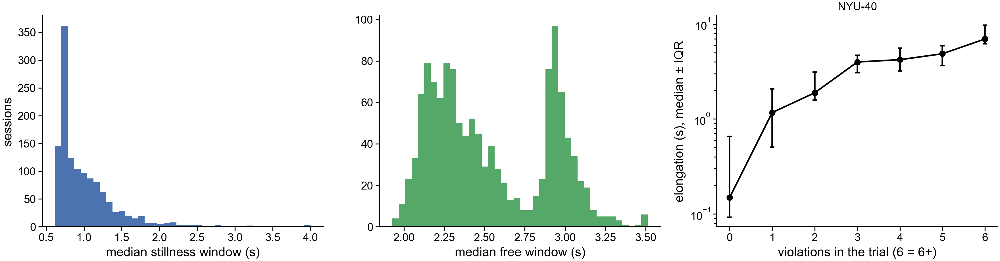

n_violations
0    0.149
1    1.169
2    1.888
3    4.947


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.5))
axs[0].hist(S['still_window_median_s'].clip(upper=4), bins=40, color='#4C72B0')
axs[0].set_xlabel('median stillness window (s)'); axs[0].set_ylabel('sessions')
axs[1].hist(S['free_window_median_s'], bins=40, color='#55A868')
axs[1].set_xlabel('median free window (s)')

# per trial, one mouse's first and last session
rows = []
t = es.mouse_trials(ex)
for si in (1, n_ex):
    tt = t[t.session_index == si].reset_index(drop=True)
    sess = tt['session'].iloc[0]
    dm = pd.read_parquet(es.DM_DIR / f'design_matrix_{sess}_{ex}').dropna().sort_values('Bin')
    onsets, _, _ = es.wheel_onsets(dm['Bin'].to_numpy(float), dm['avg_wheel_vel'].to_numpy(float))
    lo, hi = es.trial_windows(tt)['still']
    rows.append(pd.DataFrame({'n_violations': es.count_in(onsets, lo, hi),
                              'elongation': (tt['goCue_times'] - tt['quiescence'] - tt['intervals_0']).to_numpy()}))
pt = pd.concat(rows)
g = pt.groupby(pt['n_violations'].clip(upper=6))['elongation']
axs[2].errorbar(g.median().index, g.median(), yerr=[g.median() - g.quantile(.25), g.quantile(.75) - g.median()],
                fmt='o-', color='k', ms=3, lw=1)
axs[2].set_yscale('log'); axs[2].set_xlabel('violations in the trial (6 = 6+)')
axs[2].set_ylabel('elongation (s), median ± IQR'); axs[2].set_title(ex, fontsize=7)
plt.tight_layout(); plt.show()
print(pt.groupby(pt['n_violations'].clip(upper=3))['elongation'].median().round(3).to_string())

## Trajectories over training

Each measure per session, for the 64 complete mice. Thin lines = individual mice; thick lines = the
median of each learning-speed third.

* **Left:** by session number. Slow learners have more sessions, so the right-hand end is made up
  of slow learners only. The number of mice per session is shown underneath.
* **Middle:** by **fraction of training completed** (session 1 = 0, last session before proficiency
  = 1), in 10 bins. Every mouse contributes to every bin, so learning-speed thirds can be compared
  on the same axis.
* **Right:** aligned to the session in which the third contrast is first added (0). This is the first
  stage criterion, so it asks what changes around the point where the mouse first meets it.
  Medians are drawn only where at least 4 mice contribute.

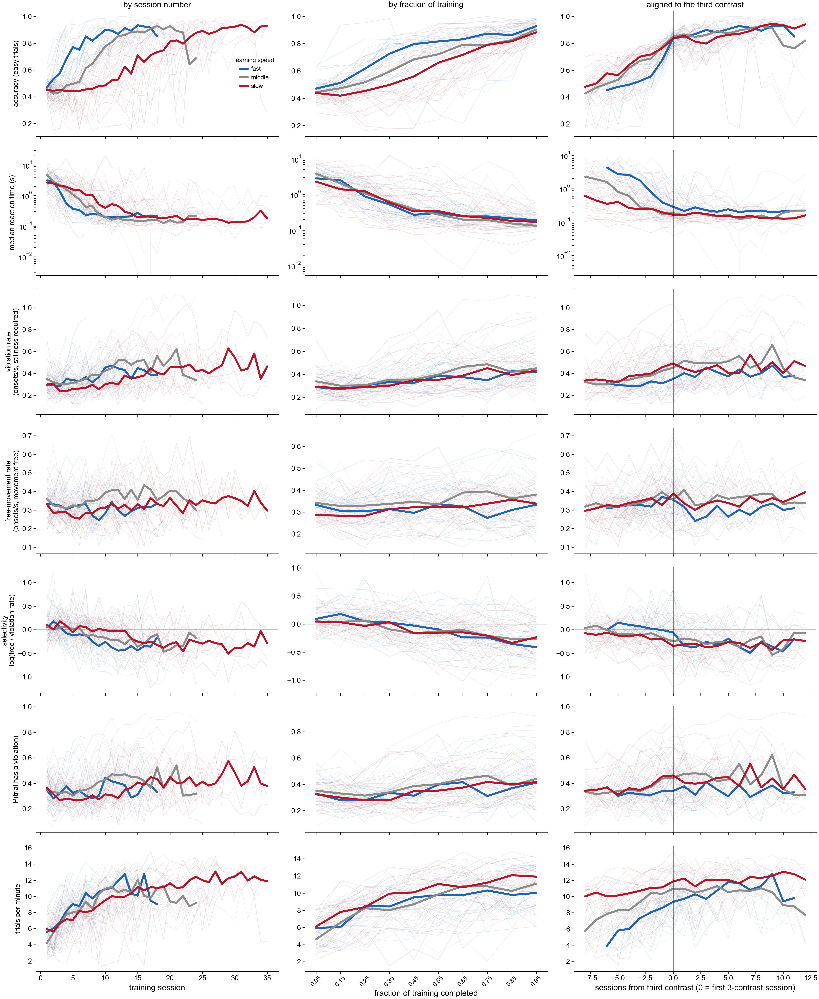

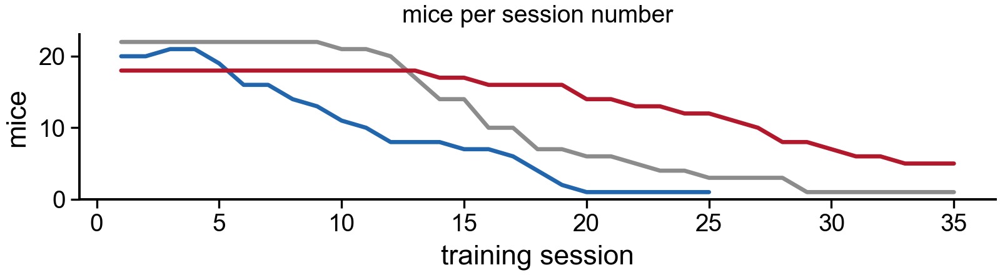

In [4]:
MEASURES = [('accuracy_easy', 'accuracy (easy trials)', False),
            ('rt_median_s', 'median reaction time (s)', True),
            ('still_rate', 'violation rate\n(onsets/s, stillness required)', False),
            ('free_rate', 'free-movement rate\n(onsets/s, movement free)', False),
            ('selectivity', 'selectivity\nlog(free / violation rate)', False),
            ('p_trial_violation', 'P(trial has a violation)', False),
            ('trials_per_min', 'trials per minute', False)]
MAX_SESS = 35
NBIN = 10
C['frac_bin'] = np.minimum((C['training_fraction'] * NBIN).astype(int), NBIN - 1)

REL = (-8, 12)                       # sessions around the third-contrast session
fig, axs = plt.subplots(len(MEASURES), 3, figsize=(11.5, 2.0 * len(MEASURES)), sharex='col')
for i, (col, lbl, logy) in enumerate(MEASURES):
    for j, xcol in enumerate(['session_index', 'frac_bin', 'rel_3c']):
        ax = axs[i, j]
        d = (C[C['session_index'] <= MAX_SESS] if j == 0 else
             C if j == 1 else C[C['rel_3c'].between(*REL)])
        for m, g in d.groupby('mouse_name'):
            gg = g.groupby(xcol)[col].mean()
            ax.plot(gg.index, gg.values, color=T_COL[g['tercile'].iloc[0]], alpha=0.12, lw=0.5)
        for tc, c in T_COL.items():
            gm = d[d.tercile == tc].groupby(['mouse_name', xcol])[col].mean().groupby(xcol)
            med, n = gm.median(), gm.size()
            med = med[n >= 4]
            ax.plot(med.index, med.values, color=c, lw=2, label=tc)
        if logy:
            ax.set_yscale('log')
        if j == 0:
            ax.set_ylabel(lbl, fontsize=7)
        if col == 'selectivity':
            ps.zero_line(ax)
        if j == 2:
            ax.axvline(0, color='k', lw=0.6, alpha=0.6)
axs[0, 0].legend(fontsize=6, frameon=False, title='learning speed', title_fontsize=6)
axs[-1, 0].set_xlabel('training session')
axs[-1, 1].set_xlabel('fraction of training completed')
axs[-1, 1].set_xticks(range(NBIN)); axs[-1, 1].set_xticklabels([f'{(k + .5) / NBIN:.2f}' for k in range(NBIN)],
                                                              rotation=45, fontsize=6)
axs[-1, 2].set_xlabel('sessions from third contrast (0 = first 3-contrast session)')
axs[0, 0].set_title('by session number', fontsize=8); axs[0, 1].set_title('by fraction of training', fontsize=8)
axs[0, 2].set_title('aligned to the third contrast', fontsize=8)
plt.tight_layout(); plt.show()

ns = C[C.session_index <= MAX_SESS].groupby(['session_index', 'tercile'], observed=True)['mouse_name'].nunique().unstack()
fig, ax = plt.subplots(figsize=(4.2, 1.3))
for tc, c in T_COL.items():
    ax.plot(ns.index, ns[tc], color=c, lw=1.2)
ax.set_xlabel('training session'); ax.set_ylabel('mice'); ax.set_title('mice per session number', fontsize=7)
plt.tight_layout(); plt.show()

### The same trajectories in numbers

Median per learning-speed third, at the start (first 10% of training), the middle (40–60%) and the
end (last 10%) of training.

In [5]:
stage = pd.cut(C['training_fraction'], [-0.01, 0.1, 0.4, 0.6, 0.9, 1.0],
               labels=['start (0-10%)', 'early-mid', 'middle (40-60%)', 'mid-late', 'end (90-100%)'])
C['stage'] = stage
cols = [m[0] for m in MEASURES]
tab = (C[C.stage.isin(['start (0-10%)', 'middle (40-60%)', 'end (90-100%)'])]
       .groupby(['tercile', 'stage', 'mouse_name'], observed=True)[cols].mean()
       .groupby(['tercile', 'stage'], observed=True).median())
tab.round(3)

accuracy_easy  rt_median_s  still_rate  free_rate  \
tercile stage                                                                
fast    start (0-10%)            0.473        2.846       0.288      0.333   
        middle (40-60%)          0.788        0.305       0.363      0.391   
        end (90-100%)            0.928        0.203       0.421      0.333   
middle  start (0-10%)            0.445        3.856       0.333      0.338   
        middle (40-60%)          0.722        0.350       0.399      0.355   
        end (90-100%)            0.905        0.132       0.451      0.380   
slow    start (0-10%)            0.439        2.293       0.292      0.284   
        middle (40-60%)          0.613        0.340       0.343      0.332   
        end (90-100%)            0.883        0.172       0.433      0.338   

                         selectivity  p_trial_violation  trials_per_min  
tercile stage                                                            
fast    start (0-10%)          0.092              0.329           5.949  
        middle (40-60%)        0.010              0.359           9.360  
        end (90-100%)         -0.386              0.412          10.019  
middle  start (0-10%)          0.042              0.352           4.622  
        middle (40-60%)       -0.094              0.393           9.638  
        end (90-100%)         -0.297              0.441          11.104  
slow    start (0-10%)          0.026              0.318           6.107  
        middle (40-60%)       -0.159              0.356          10.373  
        end (90-100%)         -0.223              0.416          11.955

## Diagnostic: when after feedback does the mouse start moving?

The sanity-check trace shows a problem with the window-based measures. Late in training, many
"violations" happen right at the start of the stillness window. But **the mouse is not told when a
trial starts**: the stillness window begins silently, about 2.2 s after a correct feedback (3.1 s
after an error, which has a longer ITI). The go cue comes about 1.2 s later. The free window and the
start of the stillness window therefore look identical to the mouse. The only cue it has that the
stimulus is coming is **time since the last feedback**.

So this shows the movement-onset rate as a function of time since the previous feedback, until the
go cue of the next trial. Each session's rate is onsets / trial-seconds at risk per 100 ms bin.
Sessions are averaged per mouse within each stage of training, then the median is taken across mice.
After-correct and after-error trials are shown separately because their timelines differ by ~1 s.
Dotted line = median trial start; solid line = median go cue.

A mouse that knows the structure, and uses elapsed time as its clock, should suppress onsets in the
second or so before the stimulus, while still moving early in the ITI.

/var/folders/nt/d2j3zp9d1xzb8wgfrw81j0c40000gn/T/ipykernel_54009/4174506882.py:18: RuntimeWarning: All-NaN slice encountered
  ax.plot(cent, np.nanmedian(rate, 0), color=col, lw=1.3, label=f'{st} (n = {len(rate)})')


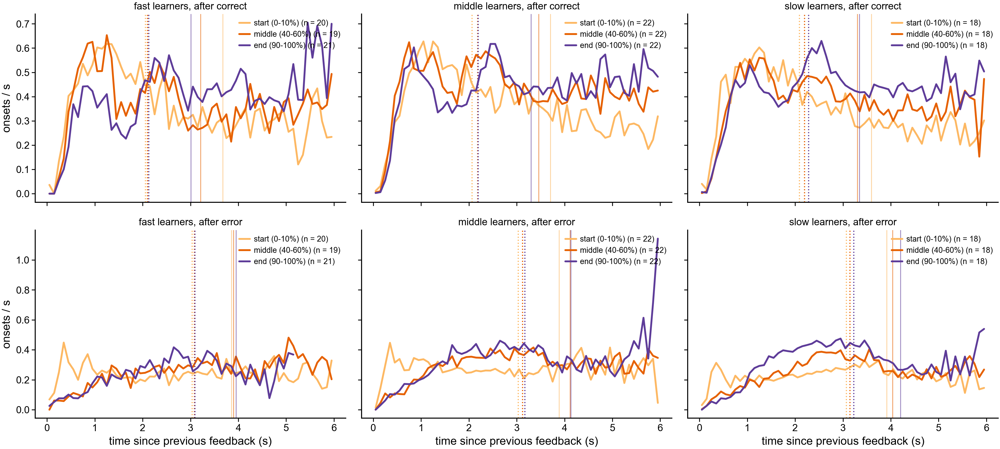

In [6]:
H = es.build_hazard(S)              # cached; es.build_hazard(S, refresh=True) recomputes
nb_ = len(es.HAZ_EDGES) - 1
cent = (es.HAZ_EDGES[:-1] + es.HAZ_EDGES[1:]) / 2
H = H.merge(C[['session', 'stage', 'tercile']], on='session')
STAGE_COL = {'start (0-10%)': '#FDB863', 'middle (40-60%)': '#E66101', 'end (90-100%)': '#5E3C99'}

fig, axs = plt.subplots(2, 3, figsize=(10, 4.6), sharex=True, sharey='row')
for r, prev in enumerate(['correct', 'error']):
    for c_, tc in enumerate(T_COL):
        ax = axs[r, c_]
        for st, col in STAGE_COL.items():
            d = H[(H.prev == prev) & (H.stage == st) & (H.tercile == tc)]
            if not len(d):
                continue
            n = d[[f'n{k}' for k in range(nb_)]].groupby(d.mouse_name).sum().to_numpy()
            e = d[[f'e{k}' for k in range(nb_)]].groupby(d.mouse_name).sum().to_numpy()
            rate = np.where(e > 5, n / np.maximum(e, 1e-9), np.nan)        # need >= 5 trial-s at risk
            ax.plot(cent, np.nanmedian(rate, 0), color=col, lw=1.3, label=f'{st} (n = {len(rate)})')
            ax.axvline(d['start_delay'].median(), color=col, ls=':', lw=0.8)
            ax.axvline(d['go_delay'].median(), color=col, ls='-', lw=0.6, alpha=0.6)
        ax.set_title(f'{tc} learners, after {prev}', fontsize=7)
        if c_ == 0:
            ax.set_ylabel('onsets / s')
        if r == 1:
            ax.set_xlabel('time since previous feedback (s)')
        ax.legend(fontsize=5.5, frameon=False, loc='upper right')
plt.tight_layout(); plt.show()

## The time-since-feedback view

The diagnostic above is turned into per-session measures. Each trial's windows are defined from *its
own* previous feedback and its own silent trial start, separately after correct and after error trials:

| window | from → to | what the task says |
|---|---|---|
| **reward** | feedback → +0.5 s | free (response tail, reward consumption) |
| **ITI** | feedback + 0.5 s → trial start − 0.4 s | free |
| **pre** | trial start − 0.4 s → trial start | free: the last moment before the rule applies |
| **post** | trial start → trial start + 0.4 s | stillness required, but no go cue is possible yet |

**boundary** = log(onset rate in *post*) − log(onset rate in *pre*).
* It is 0 if the mouse doesn't distinguish the moment the silent trial start passes.
* It is below 0 if the mouse keeps stiller once stillness becomes required. A mouse can only manage
  that by timing elapsed time since feedback.

**Why every window stops before the go cue.** A go cue arrives only after the mouse has been still,
so close to it the trials still waiting are enriched for mice that moved, and rates there are biased
upward. The earliest possible go cue is trial start + ≈ 0.47 s, so the *post* window (0.4 s) is clean.
In the heatmaps below, the time axis is cut at the same point: ≈ 2.6 s after a correct trial and
≈ 3.6 s after an error.

In [7]:
F = es.build_feedback(S)            # cached; es.build_feedback(S, refresh=True) recomputes (~30 s)
F = F.merge(C[['session', 'mouse_name', 'session_index', 'training_fraction', 'frac_bin', 'rel_3c',
               'tercile', 'stage']], on=['session', 'mouse_name'])
print(F.groupby('prev')[['n_trials', 'start_delay']].median().round(2).to_string())

         n_trials  start_delay
prev                          
correct     383.5         2.15
error       184.0         3.12


### How the post-feedback profile changes over training

Onset rate (per s) as a function of time since the previous feedback. Rows = fraction of training
completed, in 10 bins; columns = time. Each cell is the median across mice of each mouse's rate,
pooled over its sessions in that bin. The dotted line is the median silent trial start. The axis
ends at the earliest possible go cue.

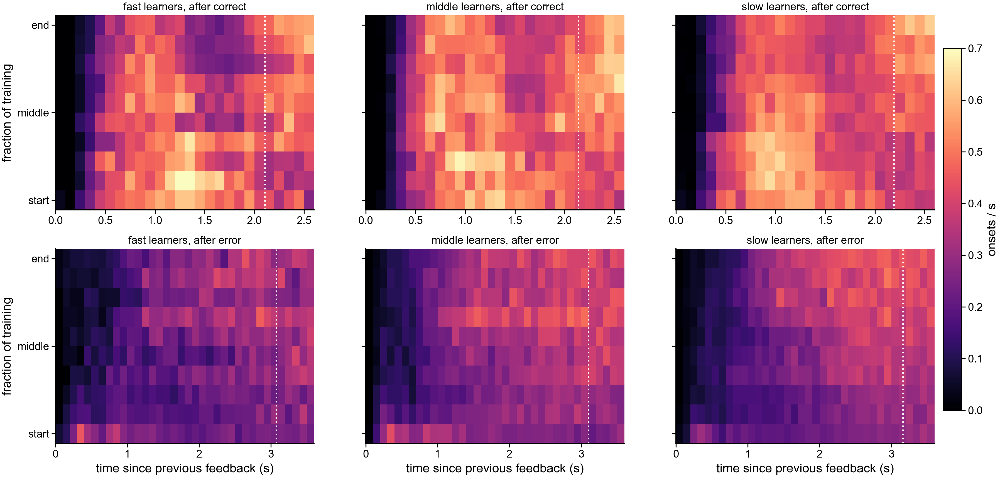

In [8]:
CUT = {'correct': 2.6, 'error': 3.6}
Hc = H.drop(columns=['stage', 'tercile']).merge(C[['session', 'frac_bin', 'tercile']], on='session')
fig, axs = plt.subplots(2, 3, figsize=(10.5, 5), sharey=True)
for r, prev in enumerate(['correct', 'error']):
    kmax = int(round(CUT[prev] / 0.1))
    for c_, tc in enumerate(T_COL):
        ax = axs[r, c_]
        M = np.full((NBIN, kmax), np.nan)
        for fb_ in range(NBIN):
            d = Hc[(Hc.prev == prev) & (Hc.tercile == tc) & (Hc.frac_bin == fb_)]
            if not len(d):
                continue
            n = d[[f'n{k}' for k in range(kmax)]].groupby(d.mouse_name).sum().to_numpy()
            e = d[[f'e{k}' for k in range(kmax)]].groupby(d.mouse_name).sum().to_numpy()
            M[fb_] = np.nanmedian(np.where(e > 5, n / np.maximum(e, 1e-9), np.nan), 0)
        im = ax.imshow(M, aspect='auto', origin='lower', cmap='magma', vmin=0, vmax=0.7,
                       extent=[0, kmax * 0.1, -0.5, NBIN - 0.5])
        sd = Hc.loc[(Hc.prev == prev) & (Hc.tercile == tc), 'start_delay'].median()
        ax.axvline(sd, color='w', ls=':', lw=1)
        ax.set_title(f'{tc} learners, after {prev}', fontsize=7)
        if c_ == 0:
            ax.set_ylabel('fraction of training')
            ax.set_yticks([0, 4.5, 9]); ax.set_yticklabels(['start', 'middle', 'end'])
        if r == 1:
            ax.set_xlabel('time since previous feedback (s)')
fig.colorbar(im, ax=axs, fraction=0.02, pad=0.01, label='onsets / s')
plt.show()

### Trajectories of the time-since-feedback measures

The same layout as the window-based trajectories: thin lines are mice, thick lines are learning-speed
medians. Left: by fraction of training. Right: aligned to the third contrast. Rows give each measure
after correct and after error trials.

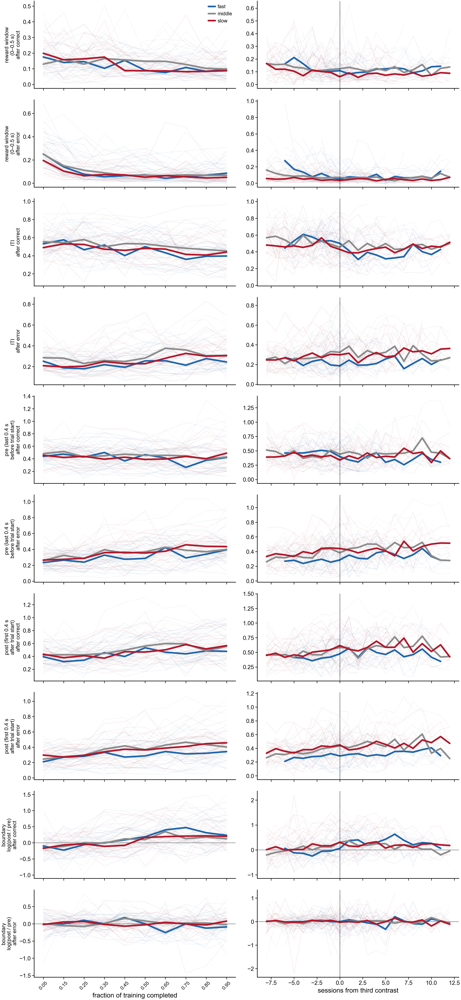

reward_rate  iti_rate  pre_rate  post_rate  \
prev    tercile stage                                                         
correct fast    start (0-10%)          0.165     0.532     0.440      0.393   
                middle (40-60%)        0.104     0.525     0.395      0.533   
                end (90-100%)          0.076     0.397     0.447      0.477   
        middle  start (0-10%)          0.130     0.554     0.480      0.418   
                middle (40-60%)        0.149     0.515     0.512      0.554   
                end (90-100%)          0.099     0.453     0.426      0.557   
        slow    start (0-10%)          0.189     0.490     0.456      0.432   
                middle (40-60%)        0.104     0.490     0.401      0.470   
                end (90-100%)          0.088     0.438     0.473      0.565   
error   fast    start (0-10%)          0.251     0.252     0.224      0.210   
                middle (40-60%)        0.061     0.255     0.286      0.310   
                end (90-100%)          0.091     0.238     0.365      0.343   
        middle  start (0-10%)          0.249     0.286     0.259      0.244   
                middle (40-60%)        0.075     0.304     0.371      0.405   
                end (90-100%)          0.068     0.328     0.413      0.402   
        slow    start (0-10%)          0.190     0.208     0.265      0.297   
                middle (40-60%)        0.063     0.240     0.376      0.364   
                end (90-100%)          0.050     0.310     0.434      0.457   

                                 boundary  
prev    tercile stage                      
correct fast    start (0-10%)      -0.105  
                middle (40-60%)     0.143  
                end (90-100%)       0.233  
        middle  start (0-10%)      -0.154  
                middle (40-60%)     0.148  
                end (90-100%)       0.124  
        slow    start (0-10%)      -0.141  
                middle (40-60%)     0.061  
                end (90-100%)       0.201  
error   fast    start (0-10%)      -0.020  
                middle (40-60%)     0.120  
                end (90-100%)      -0.059  
        middle  start (0-10%)      -0.001  
                middle (40-60%)     0.069  
                end (90-100%)      -0.024  
        slow    start (0-10%)      -0.022  
                middle (40-60%)    -0.036  
                end (90-100%)       0.077

In [9]:
FB_MEAS = [('reward_rate', 'reward window\n(0–0.5 s)'), ('iti_rate', 'ITI'),
           ('pre_rate', 'pre (last 0.4 s\nbefore trial start)'), ('post_rate', 'post (first 0.4 s\nafter trial start)'),
           ('boundary', 'boundary\nlog(post / pre)')]
rows_ = [(m, lbl, prev) for m, lbl in FB_MEAS for prev in ('correct', 'error')]
fig, axs = plt.subplots(len(rows_), 2, figsize=(8, 1.7 * len(rows_)), sharex='col')
for i, (col, lbl, prev) in enumerate(rows_):
    for j, xcol in enumerate(['frac_bin', 'rel_3c']):
        ax = axs[i, j]
        d = F[F.prev == prev]
        d = d if j == 0 else d[d['rel_3c'].between(*REL)]
        for m, g in d.groupby('mouse_name'):
            gg = g.groupby(xcol)[col].mean()
            ax.plot(gg.index, gg.values, color=T_COL[g['tercile'].iloc[0]], alpha=0.1, lw=0.5)
        for tc, c in T_COL.items():
            gm = d[d.tercile == tc].groupby(['mouse_name', xcol])[col].mean().groupby(xcol)
            med, n = gm.median(), gm.size()
            ax.plot(med[n >= 4].index, med[n >= 4].values, color=c, lw=2, label=tc)
        if col == 'boundary':
            ps.zero_line(ax)
        if j == 1:
            ax.axvline(0, color='k', lw=0.6, alpha=0.6)
        if j == 0:
            ax.set_ylabel(f'{lbl}\nafter {prev}', fontsize=6.5)
axs[0, 0].legend(fontsize=6, frameon=False)
axs[-1, 0].set_xlabel('fraction of training completed')
axs[-1, 0].set_xticks(range(NBIN)); axs[-1, 0].set_xticklabels([f'{(k + .5) / NBIN:.2f}' for k in range(NBIN)],
                                                              rotation=45, fontsize=6)
axs[-1, 1].set_xlabel('sessions from third contrast')
plt.tight_layout(); plt.show()

fb_tab = (F[F.stage.isin(['start (0-10%)', 'middle (40-60%)', 'end (90-100%)'])]
          .groupby(['prev', 'tercile', 'stage', 'mouse_name'], observed=True)[[m for m, _ in FB_MEAS]].mean()
          .groupby(['prev', 'tercile', 'stage'], observed=True).median())
fb_tab.round(3)

## Which clock does the mouse use: time since feedback, or time to the trial start?

The ITI is about 1 s longer after an error than after a correct trial, so the silent trial start comes
≈ 2.2 s after a correct feedback and ≈ 3.1 s after an error. That difference is used here as a test.

* **Feedback clock:** if the mouse times from feedback regardless of outcome, the post-error profile
  should match the post-correct one when both are **aligned to feedback**.
* **Trial-start clock:** if the mouse has learned that the wait depends on the outcome, the profiles
  should match when **aligned to the trial start**.

**Comparison segments.** Both are 2.0 s (20 bins of 0.1 s):
* feedback-aligned: 0.5 → 2.5 s after feedback;
* start-aligned: 1.6 s before → 0.4 s after the trial start.

After a correct trial these two segments are nearly the same data, since the correct trial start sits
at ≈ 2.15 s. Only the post-error segment moves, by about 1 s. Both segments skip the first 0.5 s after
feedback (reward consumption, or the start of the error sound) and stop before the earliest possible
go cue.

**Measure.** For each mouse and each fifth of training, rates are pooled over that mouse's sessions,
and the correct and error profiles are correlated within each alignment: *r*_feedback and
*r*_start. The **clock index** = *r*_start − *r*_feedback. It is above 0 when the trial-start
alignment fits better.

The comparison uses shape (correlation), not level, because after an error mice move less overall
(see the same-length free window below). Note that the error sound occupies the start of the
post-error ITI, so the two outcomes differ in what the mouse hears, not only in timing. Anchoring to
the trial start sidesteps that.

In [10]:
Hs = es.build_start_hazard(S)       # cached; es.build_start_hazard(S, refresh=True) recomputes
STAGES5 = pd.cut(C['training_fraction'], [-0.01, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[0, 1, 2, 3, 4]).astype(int)
stage5 = dict(zip(C['session'], STAGES5))
STAGE5_NAME = ['0-20%', '20-40%', '40-60%', '60-80%', '80-100%']

FB_SEG = np.arange(5, 25)                                   # feedback grid, 0.5 -> 2.5 s
st_edges = es.START_EDGES
ST_SEG = np.arange(np.searchsorted(st_edges, -1.6 - 1e-9), np.searchsorted(st_edges, 0.4 - 1e-9))
assert len(FB_SEG) == len(ST_SEG) == 20


def pooled(Htab, prev, sel_sessions, idx):
    d = Htab[(Htab.prev == prev) & Htab.session.isin(sel_sessions)]
    n = d[[f'n{k}' for k in idx]].sum().to_numpy(); e = d[[f'e{k}' for k in idx]].sum().to_numpy()
    return np.where(e > 5, n / np.maximum(e, 1e-9), np.nan)


rows = []
for (m, st5), g in C.assign(st5=C.session.map(stage5)).groupby(['mouse_name', 'st5']):
    ss = set(g.session)
    prof = {(prev, al): pooled(Hc if al == 'fb' else Hs, prev, ss, FB_SEG if al == 'fb' else ST_SEG)
            for prev in ('correct', 'error') for al in ('fb', 'start')}
    r = {}
    for al in ('fb', 'start'):
        a, b = prof[('correct', al)], prof[('error', al)]
        ok = np.isfinite(a) & np.isfinite(b)
        r[al] = np.corrcoef(a[ok], b[ok])[0, 1] if ok.sum() >= 15 and a[ok].std() > 0 and b[ok].std() > 0 else np.nan
    rows.append(dict(mouse_name=m, st5=st5, tercile=g.tercile.iloc[0], r_fb=r['fb'], r_start=r['start']))
CLK = pd.DataFrame(rows)
CLK['clock_index'] = CLK['r_start'] - CLK['r_fb']
print(CLK.groupby('st5')[['r_fb', 'r_start', 'clock_index']].median().round(2)
      .set_axis(STAGE5_NAME).to_string())

         r_fb  r_start  clock_index
0-20%    0.02    -0.07         0.01
20-40%  -0.14    -0.07        -0.05
40-60%  -0.07    -0.05        -0.04
60-80%  -0.01    -0.08        -0.05
80-100%  0.10     0.01        -0.07


### The profiles themselves, under both alignments (all mice)

Median across mice of each mouse's pooled rate. Grey shading marks the 2-s comparison segment.
Top: aligned to feedback. Bottom: aligned to the silent trial start (dotted line).

/var/folders/nt/d2j3zp9d1xzb8wgfrw81j0c40000gn/T/ipykernel_54009/1710480908.py:13: RuntimeWarning: All-NaN slice encountered
  ax.plot(x[:kmax], np.nanmedian(P, 0), color=col, lw=1.3, label=f'after {prev}')


/var/folders/nt/d2j3zp9d1xzb8wgfrw81j0c40000gn/T/ipykernel_54009/1710480908.py:13: RuntimeWarning: All-NaN slice encountered
  ax.plot(x[:kmax], np.nanmedian(P, 0), color=col, lw=1.3, label=f'after {prev}')


/var/folders/nt/d2j3zp9d1xzb8wgfrw81j0c40000gn/T/ipykernel_54009/1710480908.py:13: RuntimeWarning: All-NaN slice encountered
  ax.plot(x[:kmax], np.nanmedian(P, 0), color=col, lw=1.3, label=f'after {prev}')


/var/folders/nt/d2j3zp9d1xzb8wgfrw81j0c40000gn/T/ipykernel_54009/1710480908.py:13: RuntimeWarning: All-NaN slice encountered
  ax.plot(x[:kmax], np.nanmedian(P, 0), color=col, lw=1.3, label=f'after {prev}')


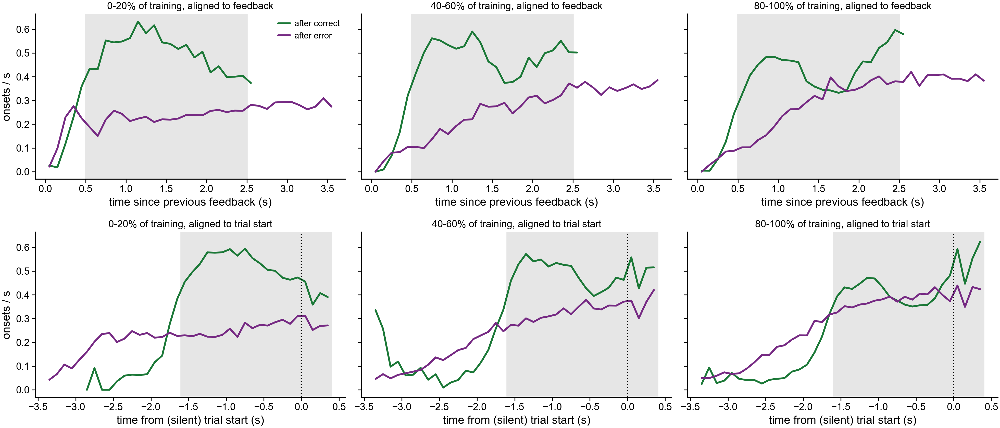

In [11]:
fig, axs = plt.subplots(2, 3, figsize=(10, 4.4), sharey=True)
xfb = (es.HAZ_EDGES[:-1] + es.HAZ_EDGES[1:]) / 2
xst = (st_edges[:-1] + st_edges[1:]) / 2
OUT_COL = {'correct': '#1B7837', 'error': '#762A83'}
for c_, st5 in enumerate([0, 2, 4]):
    sess_by_mouse = C.assign(st5=C.session.map(stage5)).query('st5 == @st5').groupby('mouse_name')['session'].apply(set)
    for r_, (al, Htab, x, kmax) in enumerate([('fb', Hc, xfb, 36), ('start', Hs, xst, len(xst))]):
        ax = axs[r_, c_]
        for prev, col in OUT_COL.items():
            P = np.vstack([pooled(Htab, prev, ss, np.arange(kmax)) for ss in sess_by_mouse])
            if al == 'fb':                                    # stop each outcome before its earliest go cue
                P[:, x[:kmax] > CUT[prev]] = np.nan
            ax.plot(x[:kmax], np.nanmedian(P, 0), color=col, lw=1.3, label=f'after {prev}')
        seg = (0.5, 2.5) if al == 'fb' else (-1.6, 0.4)
        ax.axvspan(*seg, color='0.9', zorder=0)
        if al == 'start':
            ax.axvline(0, color='k', ls=':', lw=0.8)
            ax.set_xlabel('time from (silent) trial start (s)')
        else:
            ax.set_xlabel('time since previous feedback (s)')
        ax.set_title(f'{STAGE5_NAME[st5]} of training, aligned to {"feedback" if al == "fb" else "trial start"}', fontsize=7)
        if c_ == 0:
            ax.set_ylabel('onsets / s')
axs[0, 0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

### Best shift between the two profiles

The alignment question asked continuously, pooled over all mice in each fifth of training: the
post-error profile is shifted by Δ, and its correlation with the post-correct segment (0.5–2.5 s after
feedback) is computed for each Δ. Δ = 0 is the feedback clock; the dashed line is the median difference
in trial-start delay between errors and corrects (≈ 1 s), i.e. the trial-start clock. Shifts stop at
1.0 s because later post-error bins would run past the earliest go cue.

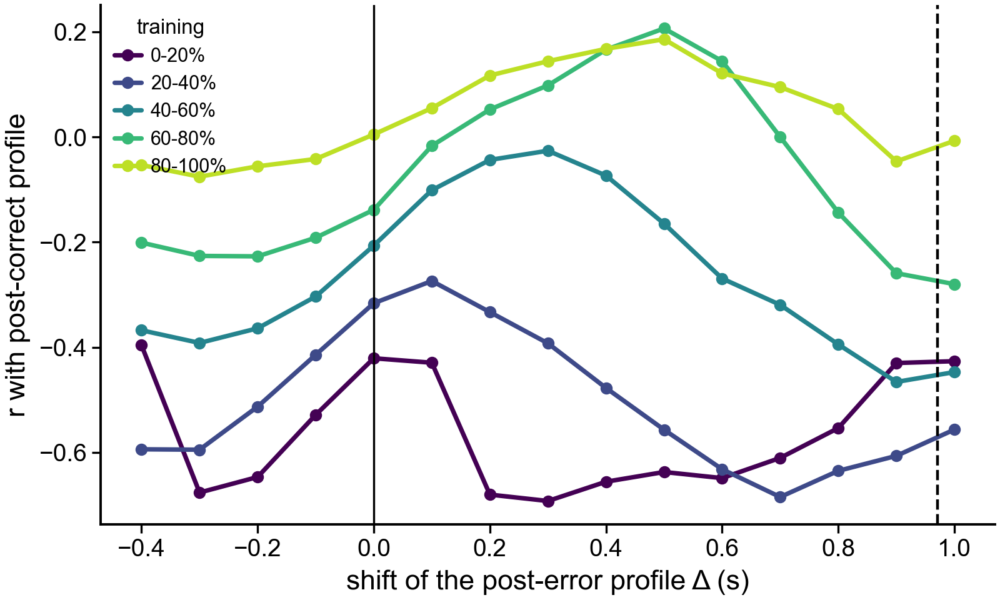

median trial-start delay difference, error - correct: 0.97 s


In [12]:
shifts = np.arange(-4, 11)                                   # in 0.1-s bins: -0.4 ... +1.0 s
d_start = (F[F.prev == 'error'].groupby('session')['start_delay'].median()
           - F[F.prev == 'correct'].groupby('session')['start_delay'].median()).median()
fig, ax = plt.subplots(figsize=(4.2, 2.6))
cols5 = plt.cm.viridis(np.linspace(0, 0.9, 5))
for st5 in range(5):
    ss = set(C.session[C.session.map(stage5) == st5])
    a = pooled(Hc, 'correct', ss, FB_SEG)
    rs = []
    for sh in shifts:
        b = pooled(Hc, 'error', ss, FB_SEG + sh)
        ok = np.isfinite(a) & np.isfinite(b)
        rs.append(np.corrcoef(a[ok], b[ok])[0, 1])
    ax.plot(shifts * 0.1, rs, color=cols5[st5], lw=1.3, marker='o', ms=2.5, label=STAGE5_NAME[st5])
ax.axvline(0, color='k', lw=0.6); ax.axvline(d_start, color='k', ls='--', lw=0.8)
ax.set_xlabel('shift of the post-error profile Δ (s)'); ax.set_ylabel('r with post-correct profile')
ax.legend(fontsize=5.5, frameon=False, title='training', title_fontsize=6)
plt.tight_layout(); plt.show()
print(f'median trial-start delay difference, error - correct: {d_start:.2f} s')

### Clock index over training, by learning speed

Per mouse and fifth of training. Left: the two correlations. Right: clock index = *r*_start −
*r*_feedback, above 0 when the trial-start clock fits better. Dots are mice; lines are learning-speed
medians.

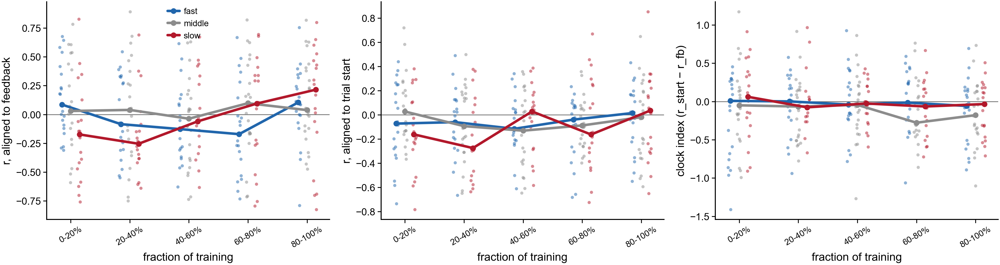

r_fb                         r_start                          \
st5         0     1     2     3     4       0     1     2     3     4   
tercile                                                                 
fast     0.09 -0.08 -0.13 -0.17  0.10   -0.07 -0.06 -0.12 -0.04  0.02   
middle   0.03  0.04 -0.04  0.10  0.04    0.03 -0.09 -0.13 -0.09 -0.02   
slow    -0.17 -0.25 -0.06  0.09  0.22   -0.16 -0.27  0.03 -0.16  0.04   

        clock_index                          
st5               0     1     2     3     4  
tercile                                      
fast           0.01  0.00 -0.04 -0.01 -0.06  
middle        -0.05 -0.07 -0.04 -0.28 -0.18  
slow           0.06 -0.08 -0.03 -0.06 -0.03

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, col, lbl in zip(axs, ['r_fb', 'r_start', 'clock_index'],
                        ['r, aligned to feedback', 'r, aligned to trial start', 'clock index (r_start − r_fb)']):
    for k, (tc, c) in enumerate(T_COL.items()):
        d = CLK[CLK.tercile == tc]
        ax.scatter(d.st5 + (k - 1) * 0.15 + np.random.default_rng(k).uniform(-0.04, 0.04, len(d)), d[col],
                   s=5, color=c, alpha=0.5, lw=0)
        med = d.groupby('st5')[col].median()
        ax.plot(med.index + (k - 1) * 0.15, med.values, color=c, lw=1.8, marker='o', ms=3, label=tc)
    ps.zero_line(ax)
    ax.set_xticks(range(5)); ax.set_xticklabels(STAGE5_NAME, rotation=30, fontsize=6)
    ax.set_ylabel(lbl); ax.set_xlabel('fraction of training')
axs[0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()
CLK.groupby(['tercile', 'st5'], observed=True)[['r_fb', 'r_start', 'clock_index']].median().unstack('st5').round(2)

### Same-length free window, after correct vs after error

`free_matched` = onset rate from 1.2 to 0.4 s before the silent trial start. It has the same length and
the same position relative to the trial start for both outcomes, unlike the ITI window above, whose
length follows the outcome. Shown with the post-error / post-correct ratio.

/opt/anaconda3/envs/iblenv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


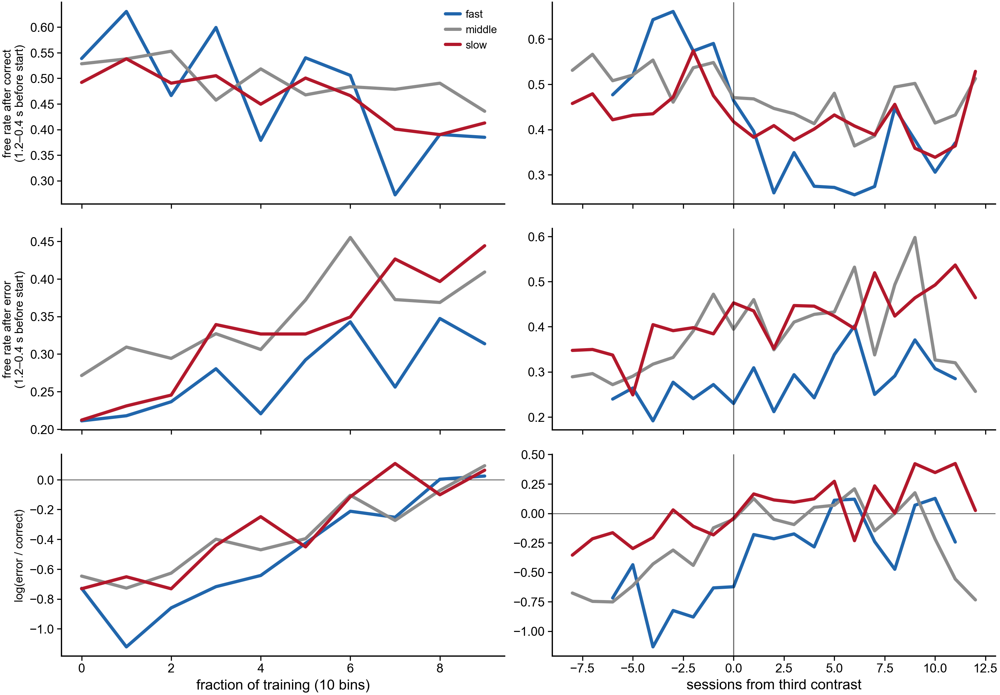

In [14]:
W2 = F.pivot_table(index=['session', 'mouse_name', 'frac_bin', 'rel_3c', 'tercile'], columns='prev',
                   values='free_matched_rate', observed=True).reset_index()
W2['log_ratio'] = np.log(W2['error'] / W2['correct'])
fig, axs = plt.subplots(3, 2, figsize=(8, 5.6), sharex='col')
for i, (col, lbl) in enumerate([('correct', 'free rate after correct\n(1.2–0.4 s before start)'),
                                 ('error', 'free rate after error\n(1.2–0.4 s before start)'),
                                 ('log_ratio', 'log(error / correct)')]):
    for j, xcol in enumerate(['frac_bin', 'rel_3c']):
        ax = axs[i, j]
        d = W2 if j == 0 else W2[W2.rel_3c.between(*REL)]
        for tc, c in T_COL.items():
            gm = d[d.tercile == tc].groupby(['mouse_name', xcol])[col].mean().groupby(xcol)
            med, n = gm.median(), gm.size()
            ax.plot(med[n >= 4].index, med[n >= 4].values, color=c, lw=1.8, label=tc)
        if col == 'log_ratio':
            ps.zero_line(ax)
        if j == 1:
            ax.axvline(0, color='k', lw=0.6, alpha=0.6)
        if j == 0:
            ax.set_ylabel(lbl, fontsize=6.5)
axs[0, 0].legend(fontsize=6, frameon=False)
axs[-1, 0].set_xlabel('fraction of training (10 bins)'); axs[-1, 1].set_xlabel('sessions from third contrast')
plt.tight_layout(); plt.show()

## Observations (descriptive; no tests yet)

**1. Mice do not learn to keep still selectively where it is required, at least by this measure.**
Over training, the violation rate *rises* (≈ 0.29 → 0.43 onsets/s from the first to the last 10% of
training) and the fraction of trials with a violation goes from ≈ 0.33 to ≈ 0.42. The free-movement
rate stays flat (≈ 0.3/s). Selectivity therefore drifts from ≈ 0 to *negative* (≈ −0.2 to −0.4).
Late in training, mice start more movements while stillness is required than while moving is free.
Accuracy rises and reaction time falls over the same sessions, so this happens while mice clearly
learn the stimulus–response part of the task.

**2. Learning-speed groups barely differ in these measures once training length is normalised.**
By fraction of training, the three thirds overlap in violation rate, free-movement rate and
selectivity. By session number they appear to differ, but that mainly reflects slow learners staying
longer at each stage. Aligned to the third contrast, slow and middle learners have somewhat more
violations around and after that point than fast learners. Fast learners also run fewer trials per
minute before reaching it (≈ 4–8 vs ≈ 10). Both are small and untested.

**3. The window-based measures assume a boundary the mouse cannot see.** Trial start is not signalled.
From the mouse's side, the free window and the first part of the stillness window are the same stretch
of time after feedback. The time-since-feedback diagnostic shows this directly:
* **After a correct trial:** onsets are suppressed for ~0.5 s (reward consumption), peak around 1 s,
  then stay at a plateau. There is **no dip before the expected go cue at any stage of training**.
  Late in training, slow learners even show a bump just after the silent trial start (~2.5 s).
* **After an error:** the picture does change with learning. Early in training there is an onset bump
  ~0.3 s after the error feedback, as if the response movement carries on. Later this disappears, and
  onsets ramp up slowly over the first ~1.5 s. This is an outcome-specific change in when the mouse
  moves, and it is the clearest candidate here for something "structural" being learned.

**4. The time-since-feedback view.** All values are medians across mice, untested.
* **After a correct trial, mice do not learn to go still at the silent trial start; they do the
  opposite.** At the start of training, onsets are slightly *less* frequent just after the trial
  start than just before (boundary ≈ −0.1 to −0.15). By mid-training the boundary is ≈ +0.1 to
  +0.2 in all three learning-speed groups: more movement starts just after the rule begins to apply.
  In the heatmap, late-training fast learners show a quiet stretch about 1.4–2.0 s after reward and
  then a rise around trial start. This looks like timed re-engagement with the wheel around when the
  next stimulus is due, i.e. the mouse has learned the timing, but it shows up as movement rather
  than as the stillness the rule asks for.
* **After an error, the post-error movement burst disappears early and in everyone.** The 0–0.5 s
  onset rate falls from ≈ 0.2–0.25 to ≈ 0.06 within the first ~20% of training, in all three groups.
  After that, mice stay still for about a second after an error. The boundary after errors stays ≈ 0
  throughout.
* **Learning-speed differences are small.** Fast learners move somewhat less after errors (ITI, pre and
  post windows) than slow learners, most visibly after the third contrast is added. Slow learners'
  rates after errors keep rising late in training.

**5. Which clock?** All values are medians, untested.
* **Pooled over mice,** the post-error profile matches the post-correct one best at a shift of
  Δ ≈ 0 early in training (feedback clock). The best shift moves to Δ ≈ 0.5 s in the last 40% of
  training. That is about half of the ≈ 1 s difference in trial-start delay, so it is neither
  clock cleanly.
* **The two profiles become more alike overall.** Early, they are anti-correlated (r ≈ −0.4 to
  −0.7): a peak after reward vs a flat profile after errors. Late, they are weakly positive. Both
  ramp up toward the trial start late in training, but the post-error ramp starts earlier and rises
  more slowly.
* **The per-mouse clock index is not usable as it stands.** Each mouse × fifth-of-training profile
  has 20 bins and only a few hundred error trials, so r_feedback and r_start are dominated by noise
  (medians ≈ 0, in every group). A per-mouse version needs a smoother model of the profile, e.g. a
  Poisson regression with a few temporal basis functions per clock, instead of raw bins.

**6. Same-length free window (1.2–0.4 s before trial start).** Movement after correct trials falls
slightly over training, and movement after errors rises. The error/correct ratio goes from
log ≈ −0.7 (much less movement after errors) to ≈ 0 by the end.
* **This is the clearest learning-speed difference in the notebook so far.** Aligned to the third
  contrast, fast learners are still at log ratio ≈ −0.6 to −0.9 in the sessions before it: they
  keep pausing after errors. Slow learners are already near −0.2.
* It is untested and comes from medians of ~20 mice per group, but it is a concrete lead: a
  **post-error pause** that fast learners keep longer.

**What this means for step 2.** "Stillness windows vs free windows" is the wrong unit, because the mouse
cannot tell them apart. The time-since-feedback framing matches what the mouse can actually use, and it
is also the clock the toy model's M1 agent is given. The natural step-2 measures are:
* how the post-feedback onset profile changes across sessions, separately after correct and after error;
* whether that change comes before or after the accuracy rise, and whether its timing differs with
  learning speed.

The quiescence rule itself may simply not be something mice learn to anticipate: the timer restarts
silently, so violations cost only time.